# Recovery and queue monitoring
**Refreshable notebook dashboard · synthetic case · no live system connection.**

Change the parameter cell, replace the two source workbooks with refreshed exports retaining the same schemas, and Run All. The notebook re-cleans raw data, validates joins, displays date/queue filters and sample denominators, and exports monitoring tables and sampled recovery-review candidates. Charts render directly in Jupyter; no server is required.

This is a historical dashboard through September 30, 2026, not evidence that a proposed intervention has happened. Default as-of is the **case date**, October 2. For a real refresh change it deliberately; historical data must not look current. Operational alert thresholds below are proposed review triggers; they are not contractual targets or causal tests.


In [1]:
# User controls. Queue must match the workbook labels.
QUEUE = 'General Care'
AS_OF = '2026-10-02'
WINDOW_DAYS = 7
BASELINE_START = '2026-08-01'
BASELINE_END = '2026-08-31'
MIN_ELIGIBLE_SAMPLE = 30
MAX_STALENESS_DAYS = 3
ABANDONMENT_DELTA_PP = 2.0
WAIT_DELTA_MIN = 0.5
COMPLETION_REVIEW_FLOOR = 0.80  # proposed target, not historical expectation


In [2]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'analysis_utils.py').exists() else Path.cwd() / 'northstar_analysis'
assert (ROOT / 'analysis_utils.py').exists(), 'Run from northstar_analysis or its parent.'
sys.path.insert(0, str(ROOT))
from analysis_utils import *
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 40)
D = load_data(as_of=AS_OF, call_through=AS_OF)
calls, ops = D['calls'], D['ops']

AS_OF = pd.Timestamp(AS_OF)
assert QUEUE in set(ops.Queue), 'Unknown queue'
assert WINDOW_DAYS > 0
latest = ops.loc[ops.Queue.eq(QUEUE), 'Date'].max()
if latest > AS_OF: raise ValueError('Source operations include dates after AS_OF; choose a valid snapshot')
end = min(latest, AS_OF)
start = end - pd.Timedelta(days=WINDOW_DAYS-1)
base = ops[ops.Queue.eq(QUEUE) & ops.Date.between(BASELINE_START, BASELINE_END)]
current = ops[ops.Queue.eq(QUEUE) & ops.Date.between(start,end)]
if base.empty or current.empty: raise ValueError('Empty baseline or current window')
stale_days = (AS_OF-latest).days
print(f'Queue: {QUEUE} | source latest: {latest.date()} | case as-of: {AS_OF.date()}')
print(f'Current: {start.date()}–{end.date()} | baseline: {BASELINE_START}–{BASELINE_END}')
print(f'Data age: {stale_days} days | '+('STALE — refresh required' if stale_days>MAX_STALENESS_DAYS else 'within configured freshness tolerance'))
print('No intervention exposure file supplied; intervention status: NOT OBSERVED.')
display(D['audit'])


Queue: General Care | source latest: 2026-09-30 | case as-of: 2026-10-02
Current: 2026-09-24–2026-09-30 | baseline: 2026-08-01–2026-08-31
Data age: 2 days | within configured freshness tolerance
No intervention exposure file supplied; intervention status: NOT OBSERVED.


,table,raw_rows,header_excel_row,missing_key,clean_rows,removed_rows
0,daily,366,5,0,366,0
1,calls,20028,5,0,20000,28
2,staff,366,5,0,366,0
3,catalog,250,5,0,250,0
4,qa,1600,5,0,1600,0
5,feedback,2200,5,0,2200,0


In [3]:
baseline = population_metrics(base)
now = population_metrics(current)
scorecard = pd.DataFrame({'baseline':baseline,'current':now,'delta':now-baseline})
display(scorecard.round(3))
scorecard.to_csv(OUT/'monitor_population_scorecard.csv')
window_calls = calls[calls.Queue.eq(QUEUE) & calls['Call date'].between(start,end)]
active_calls = window_calls[window_calls['Recovery available']]
r = recovery_metrics(active_calls)
display(r.to_frame('sampled calls — eligible denominator').round(3))
print('All sampled calls in window:',len(window_calls),'; missing product:',window_calls['Product code'].isna().sum())
# Unique event IDs are validated; these are not total Care demand or unique households.
alerts = [
 ('Freshness', 'REVIEW' if stale_days>MAX_STALENESS_DAYS else 'OK', f'{stale_days} days since latest operations'),
 ('Complete date window','OK' if len(current)==WINDOW_DAYS else 'REVIEW',f'{len(current)}/{WINDOW_DAYS} queue-days'),
 ('Abandonment','REVIEW' if 100*(now.abandonment-baseline.abandonment)>ABANDONMENT_DELTA_PP else 'Within trigger',f'{100*(now.abandonment-baseline.abandonment):.2f} pp versus baseline'),
 ('Wait proxy','REVIEW' if now.wait_min_proxy-baseline.wait_min_proxy>WAIT_DELTA_MIN else 'Within trigger',f'{now.wait_min_proxy-baseline.wait_min_proxy:.2f} min versus baseline'),
 ('Recovery sample','INSUFFICIENT' if r.eligible_n<MIN_ELIGIBLE_SAMPLE else ('REVIEW' if r.complete_rate<COMPLETION_REVIEW_FLOOR else 'Within trigger'),f'{int(r.complete_n)}/{int(r.eligible_n)} completed both; sampled calls only')]
alert_table=pd.DataFrame(alerts,columns=['check','status','evidence'])
display(alert_table)
alert_table.to_csv(OUT/'monitor_alerts.csv',index=False)


,baseline,current,delta
days,31.000,7.000,-24.000
offered,685095.000,205621.000,-479474.000
answered,656610.000,143935.000,-512675.000
offered_per_day,22099.839,29374.429,7274.590
AHT_min,8.579,11.600,3.021
wait_min_proxy,1.672,4.757,3.085
abandonment,0.042,0.300,0.258
WN7_contact_share,0.013,0.397,0.384
actual_planned,0.941,0.923,-0.018
occupancy_proxy,0.742,0.898,0.157


,sampled calls — eligible denominator
eligible_n,145.000
serial_n,114.000
replacement_n,61.000
plus_n,52.000
complete_n,52.000
complete_rate,0.359
incomplete_n,93.000


All sampled calls in window: 683 ; missing product: 6


,check,status,evidence
0,Freshness,OK,2 days since latest operations
1,Complete date window,OK,7/7 queue-days
2,Abandonment,REVIEW,25.84 pp versus baseline
3,Wait proxy,REVIEW,3.08 min versus baseline
4,Recovery sample,REVIEW,52/145 completed both; sampled calls only


**How to read the scorecard:** AHT uses answered contacts; abandonment uses offered contacts. Wait is an offered-weighted proxy because the source does not specify its underlying wait denominator. Coverage is summed actual/planned Guide-days; occupancy is scheduled-hours weighted. Full-population operational comparisons and sampled recovery results are separate. August is a pre-incident reference, not a valid causal control for a future learning rollout.

Review triggers mean investigate with WFM/Quality. A low-sample recovery window is **insufficient evidence**. Meeting a trigger does not establish improvement. Daily aggregates cannot assess the queue impact of a 12-minute learning cohort.


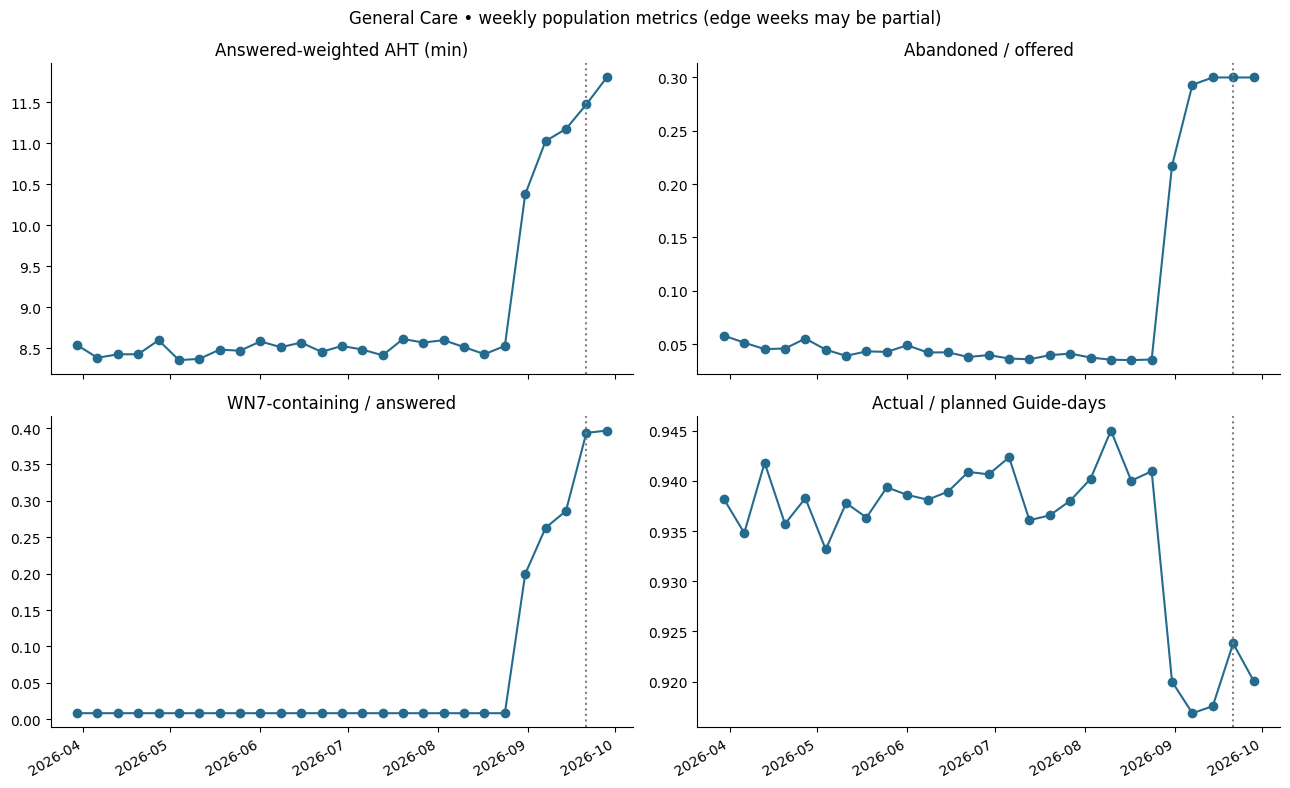

In [4]:
history = ops[ops.Queue.eq(QUEUE) & ops.Date.le(end)].copy()
history['week'] = history.Date.dt.to_period('W-SUN').dt.start_time
weekly = history.groupby('week').apply(population_metrics,include_groups=False)
fig, axes=plt.subplots(2,2,figsize=(13,8),sharex=True)
for axis,col,title in zip(axes.flat,['AHT_min','abandonment','WN7_contact_share','actual_planned'],
 ['Answered-weighted AHT (min)','Abandoned / offered','WN7-containing / answered','Actual / planned Guide-days']):
 axis.plot(weekly.index,weekly[col],marker='o',color='#246b8e');axis.set_title(title)
 axis.axvline(pd.Timestamp('2026-09-21'),color='grey',ls=':')
fig.suptitle(f'{QUEUE} • weekly population metrics (edge weeks may be partial)')
fig.autofmt_xdate();fig.tight_layout();plt.show()
weekly.to_csv(OUT/'monitor_weekly_population.csv')


,eligible_n,serial_n,replacement_n,plus_n,complete_n,complete_rate,incomplete_n
week,,,,,,,
2026-09-21,143.0,112.0,66.0,55.0,55.0,0.385,88.0
2026-09-28,61.0,47.0,23.0,21.0,21.0,0.344,40.0


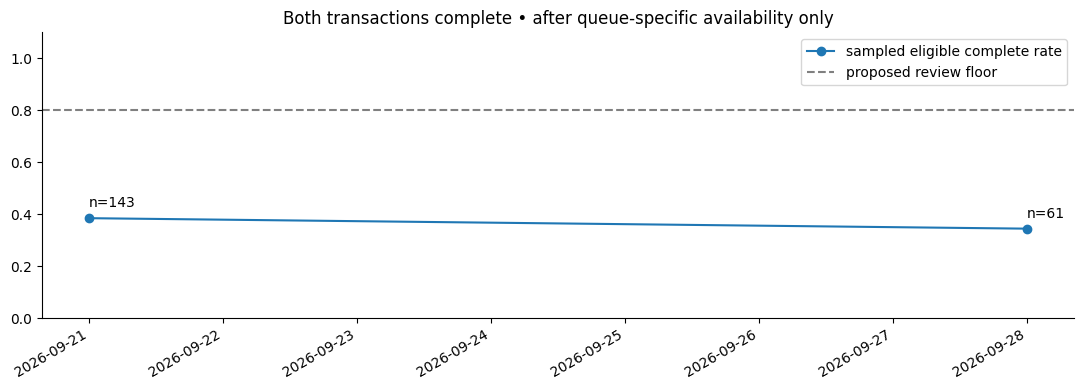

,Call ID,Call date,Queue,Serial verified,Conversation path,Replacement arranged,Northstar Plus attached,Disposition
176,ORB-26-000177,2026-09-24,General Care,No,Generic troubleshooting,No,No,Troubleshooting complete
180,ORB-26-000181,2026-09-28,General Care,Yes,Generic troubleshooting,No,No,Troubleshooting complete
726,ORB-26-000727,2026-09-25,General Care,Yes,Incomplete recovery,Yes,No,Replacement initiated
1094,ORB-26-001095,2026-09-27,General Care,Yes,Generic troubleshooting,No,No,Troubleshooting complete
1275,ORB-26-001276,2026-09-25,General Care,No,Generic troubleshooting,No,No,Troubleshooting complete
1280,ORB-26-001281,2026-09-30,General Care,No,Generic troubleshooting,No,No,Troubleshooting complete
2193,ORB-26-002194,2026-09-28,General Care,Yes,Generic troubleshooting,No,No,Troubleshooting complete
2194,ORB-26-002195,2026-09-29,General Care,Yes,Generic troubleshooting,No,No,Troubleshooting complete
2374,ORB-26-002375,2026-09-26,General Care,Yes,Generic troubleshooting,No,No,Troubleshooting complete
2378,ORB-26-002379,2026-09-30,General Care,Yes,Generic troubleshooting,No,No,Troubleshooting complete


93 sampled review candidates. Confirm current case/transaction state before any action.


In [5]:
ec = calls[calls.Queue.eq(QUEUE) & calls['Recovery available'] & calls['Call date'].le(end)].copy()
ec['week'] = ec['Call date'].dt.to_period('W-SUN').dt.start_time
wr = ec.groupby('week').apply(recovery_metrics,include_groups=False)
display(wr.round(3))
fig,ax=plt.subplots(figsize=(11,4))
if len(wr):
 ax.plot(wr.index,wr.complete_rate,marker='o',label='sampled eligible complete rate')
 for dt,row in wr.iterrows(): ax.annotate(f'n={int(row.eligible_n)}',(dt,row.complete_rate),xytext=(0,8),textcoords='offset points')
 ax.axhline(COMPLETION_REVIEW_FLOOR,color='grey',ls='--',label='proposed review floor')
 ax.set_ylim(0,1.1);ax.legend()
ax.set_title('Both transactions complete • after queue-specific availability only')
fig.autofmt_xdate();plt.tight_layout();plt.show()
wr.to_csv(OUT/'monitor_weekly_sample_recovery.csv')
# Review candidates: sampled CALLS, not open cases or unique households. No contact action is taken.
candidates=active_calls[active_calls['Eligible for recovery'].eq('Yes') & ~active_calls['Complete recovery']]
fields=['Call ID','Call date','Queue','Serial verified','Conversation path','Replacement arranged','Northstar Plus attached','Disposition']
display(candidates[fields].head(20))
candidates[fields].to_csv(OUT/'sampled_recovery_review_candidates.csv',index=False)
print(len(candidates),'sampled review candidates. Confirm current case/transaction state before any action.')


In [6]:
# QA and feedback are selected/voluntary; filter by call date AND event availability as-of.
q=D['qa_joined']; f=D['feedback_joined']
q=q[q.Queue.eq(QUEUE) & q['Call date'].between(start,end) & q['Review date'].le(AS_OF)]
f=f[f.Queue.eq(QUEUE) & f['Call date'].between(start,end) & f['Response date'].le(AS_OF)]
print('Selected QA reviews in window:',len(q),'; voluntary feedback responses:',len(f))
display(q['Selection reason'].value_counts().to_frame('review_n'))
if len(q):
 display(pd.DataFrame([{'behavior':col,'yes_n':q[col].eq('Yes').sum(),
                       'applicable_n':q[col].isin(['Yes','No']).sum()} for col in
 ['Acknowledged practical impact','Recognized recovery path','Recap complete']]))
if len(f):
 display(f.groupby('Conversation path').agg(responses=('Feedback ID','size'),mean_score=('Satisfaction score','mean')).round(2))
print('These are sample diagnostics, not population performance ratings.')


Selected QA reviews in window: 107 ; voluntary feedback responses: 377


,review_n
Selection reason,
Oversample: WN7 recovery risk,48
Oversample: long handle time,48
Routine quality sample,11


,behavior,yes_n,applicable_n
0,Acknowledged practical impact,75,107
1,Recognized recovery path,59,107
2,Recap complete,59,107


,responses,mean_score
Conversation path,,
Complete recovery,33,4.48
Generic troubleshooting,206,2.97
Incomplete recovery,3,2.33
Recognized not eligible,29,3.38
Standard resolution,106,3.62


These are sample diagnostics, not population performance ratings.


## Operating review and future instrumentation
- **Daily, Care Operations/WFM:** examine abandonment, offered volume, AHT components, coverage and occupancy; review whether coaching must be rescheduled. Annotate notices, staffing changes, search releases, routing, and actual learning exposure dates.
- **Twice weekly, Quality/Team Leads (proposed):** inspect sampled incomplete recovery and ineligible branches, serial verification and recap. Separate system pending/failure from a missed action. Validate a manageable cadence with Elias and Priya rather than add unbudgeted manager work.
- **After two weeks, Dana:** use the pilot gates in notebook 01 and a contemporaneous comparison. Expand only with recovery quality, queue protection, and sufficient evidence. No before/after causal claim from this historical dashboard.

**Unavailable metrics must stay unavailable:** household-level 7-day repeat contacts; order shipment and Plus Applied timestamps; pending backlog and age; unsupported offers to ineligible households; follow-up kept; exposure by shift/tenure; interval service levels. Current data contains call-level transaction flags but cannot verify transaction status histories or later resolution. Add authorized event feeds and a stable household/case key with appropriate access controls before implementing these metrics. Never count sampled review candidates as a population backlog.

**Refresh contract:** preserve source copies and hashes; rerun cleaning/joins and inspect audit changes. The analysis notebook retains the supplied historical cutoff. Monitoring passes its explicit `AS_OF` parameter to the loader, so refreshed calls, reviews, and responses must not extend beyond that date. Update `AS_OF` and document the new extract contract when adding genuinely later data; future-date checks remain active. No thresholds or processes here have been implemented at Northstar.
